# Setup

https://www.truefoundry.com/blog/transformer-architecture

In [1]:
from kev.checkpoint import Checkpoint, LoadOptions

ck = Checkpoint("jaredpalmer/kev-0.8b")      # downloads adapter, head.pt and config from the Hub into the HF cache
tok, model = ck.load("mps", LoadOptions())   # Qwen base + merged LoRA, pointer head loaded, eval mode

print(ck.meta.base, ck.meta.lora, ck.meta.head_dim, ck.meta.temperature)

Qwen/Qwen3.5-0.8B-Base 16 256 2.3510958125672174


# Text

In [2]:
from kev.api import SystemOneRequest, to_record, to_answers

req = SystemOneRequest(
    state="ciao! sono Piergiorgio",
    questions={
        "sentiment": {
            "type": "choice",
            "instructions": "l'utente è arrabbiato?",
            "criteria": {
                "no": "l'utente non è arrabbiato",
                "si": "l'utente è arrabbiato",
            },
        }
    },
)

rec, meta = to_record(req)        # text: state + instructions + options "name: description"
enc = model.encode(tok, rec)      # token ids, positions, segments, indices of </opt> and <decide>
print(tok.decode(enc["ids"]))   # the whole sequence, special tokens included

<|fim_prefix|>ciao! sono Piergiorgio<|fim_middle|>l'utente è arrabbiato?<|box_start|>no: l'utente non è arrabbiato<|box_end|><|box_start|>si: l'utente è arrabbiato<|box_end|><|fim_suffix|>


In [3]:
probs= model.probs(enc)
probs

[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


[tensor([0.8303, 0.1697])]

# Image

In [4]:
from PIL import Image
from kev_image import KevImage

kv = KevImage(ck, tok, model, "mps")

In [5]:
req = SystemOneRequest(
    state="Photo of the object to throw away:",
    questions={
        "bin": {
            "type": "choice",
            "instructions": "Which bin does this object go in?",
            "criteria": {
                "paper": "Paper and cardboard",
                "plastic": "Plastic and metal packaging: bottles, cans, tins",
                "glass": "Glass bottles and jars",
                "organic": "Food waste",
                "general": "Everything else",
            },
        }
    },
)

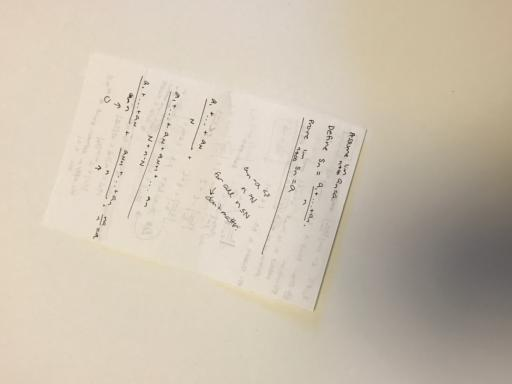

In [6]:
img_path = "data/imgs/carta_1.jpg"
img = Image.open(img_path).convert("RGB")
display(img)

In [7]:
kv.probs(req, image=img)

{'bin': {'paper': 0.5662401914596558,
  'plastic': 0.03799058869481087,
  'glass': 0.014291010797023773,
  'organic': 0.12916316092014313,
  'general': 0.25231510400772095}}

# Streaming from the webcam

This section needs a camera. The cells below start it from the notebook: the built-in camera of the Mac, or a phone with DroidCam (see the comment in the cell with `start()`). No camera? Skip this section: the cells above work without it.

## Classifier

In [8]:
def classify(kv, img):
    req = SystemOneRequest(
    state="Webcam photo of a person who is supposed to be working at the computer: ",
    questions={
        "bin": {
            "type": "choice",
            "instructions": "Is this person using his phone and getting distracted?",
            "criteria": {
                "NO_phone": "no phone in sight, the user is focused on the job ",
                "YES_phone": "the user is using his phone, wake him up"
            },
        }
    },
    )
    return kv.probs(req, image=img)

## Alarm sound

In [9]:
import io, base64, urllib.request
from pathlib import Path
import numpy as np
import soundfile as sf
from IPython.display import HTML

# French national alert siren (CC0, BigSoundBank): downloaded once
SIREN = Path("assets/nuclear_alarm.mp3")
if not SIREN.exists():
    r = urllib.request.Request("https://bigsoundbank.com/UPLOAD/mp3/3259.mp3", headers={"User-Agent": "Mozilla/5.0"})
    SIREN.write_bytes(urllib.request.urlopen(r).read())

# the siren from second 2, for 30 seconds, then looped
START = 2                                             # second it starts from
DURATION = 30                                         # seconds kept before restarting
y, sr = sf.read(SIREN)
if y.ndim > 1:
    y = y.mean(1)
clip = y[START * sr:(START + DURATION) * sr][::2]     # [::2] halves the file size, the siren does not change
buf = io.BytesIO()
sf.write(buf, clip / np.abs(clip).max(), sr // 2, format="WAV", subtype="PCM_16")
ALARM = HTML(f'<audio autoplay loop src="data:audio/wav;base64,{base64.b64encode(buf.getvalue()).decode()}"></audio>')

## Webcam: video with caption

In [10]:
from IPython.display import HTML
from webcam import BROWSER_URL, grab_frame, show, start

def video_html(caption, alarm):
    """The live video with a caption on top: green, or white on red and blinking when alarm is True."""
    style = "color:#fff;background:#d00;padding:.1em .4em;animation:blink .4s steps(2) infinite;" if alarm else "color:#3ef07a;"
    return (
        "<style>@keyframes blink { 50% { opacity:.25 } }</style>"
        '<div style="position:relative;width:640px;height:480px;background:#000">'
        f'<iframe src="{BROWSER_URL}/" width="640" height="480" frameborder="0" scrolling="no"></iframe>'
        '<div style="position:absolute;left:0;right:0;bottom:6%;text-align:center;'
        "font:900 28px/1.1 Impact,'Arial Black',sans-serif;-webkit-text-stroke:1px #000;text-shadow:0 0 8px #000;"
        f'{style}">{caption}</div></div>'
    )

In [11]:
start()   # the built-in camera of the Mac (macOS asks for permission the first time)
# start(url="http://<phone-ip>:4747/video")   # or a phone with DroidCam: use the address the app shows
show()    # the plain camera (no caption), as HTML inside the notebook

## Live loop

In [12]:
import time
from IPython.display import display, HTML

THRESHOLD = 0.51                                      # probability of "YES_phone" above which the user counts as on the phone
DELAY = 0.1                                           # seconds of phone in a row before the siren
MIN_PLAY = 3                                          # seconds the siren plays anyway, once started
video_out = display(HTML(video_html("NO PHONE DETECTED", False)), display_id=True)
probs_out = display(None, display_id=True)
label_out = display(None, display_id=True)
alarm_out = display(None, display_id=True)
playing = False
started_at = 0
phone_since = None
last_caption = None
try:
    while True:
        img = grab_frame()
        img.thumbnail((640, 640))                     # shrinks without distorting
        probs = classify(kv, img)["bin"]
        probs_out.update(probs)
        label_out.update(HTML(f"<h1 style='font-size:64px'>{max(probs, key=probs.get)}</h1>"))

        detected = probs["YES_phone"] > THRESHOLD
        caption = ("PHONE DETECTED, DROP THE PHONE NOW", True) if detected else ("NO PHONE DETECTED", False)
        if caption != last_caption:                   # redraw the caption on the video only when it changes
            video_out.update(HTML(video_html(*caption)))
            last_caption = caption

        if detected:
            if phone_since is None:
                phone_since = time.time()             # the stopwatch starts
        else:
            phone_since = None                        # phone down: reset

        too_long = phone_since is not None and time.time() - phone_since >= DELAY
        if too_long and not playing:
            alarm_out.update(ALARM)                   # siren from second 2, looped
            playing = True
            started_at = time.time()
        elif playing and phone_since is None and time.time() - started_at >= MIN_PLAY:
            alarm_out.update(HTML(""))                # phone down and 3 seconds passed: stop
            playing = False
except KeyboardInterrupt:
    alarm_out.update(HTML(""))
    video_out.update(HTML(video_html("NO PHONE DETECTED", False)))

{'NO_phone': 0.6058872938156128, 'YES_phone': 0.3941127359867096}